<a href="https://colab.research.google.com/github/ArifahZhafirah/PCVK26_04_Arifah/blob/main/P9_Week9_04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#D. PRAKTIKUM MORFOLOGI

1. Buka https://colab.research.google.com/. Setelah dipastikan bahwa google Colab
terhubung dengan Github Anda, lanjutkan dengan memilih repository yang telah
digunakan pada praktikum minggu lalu, rename file menjadi “Week9.ipynb”.

Kemudian import folder yang ada di Drive Anda dengan cara sebagai berikut.

In [14]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


2. Import beberapa library berikut yang akan digunakan selama uji coba praktikum minggu
ke-9 berikut.

In [46]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

folder = '/content/drive/MyDrive/Semester5/PCVK/P9_Arifah_04/'
daftar_gambar = ['plat_nomer.png', 'noisy_text.png']

3. Buatlah fungsi dilasi serta tampilkan hasil dilasi pada citra dengan Structuring Element
Dilasi (SED) berbentuk cross 3 x 3 tanpa menggunakan library morphology dari
openCV, sehingga menghasilkan tampilan seperti di bawah ini:

In [47]:
#Dilasi tanpa library

def dilasi_citra(F,w):
  #size image
  p,q= F.shape

  imgD= np.zeros((p,q), dtype=np.uint8)

  #Generate structure element dilasi (SED)
  SED= np.ones((w,w), dtype=np.uint8)
  constant1= (w-1)//2

  #Proses Dilasi
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

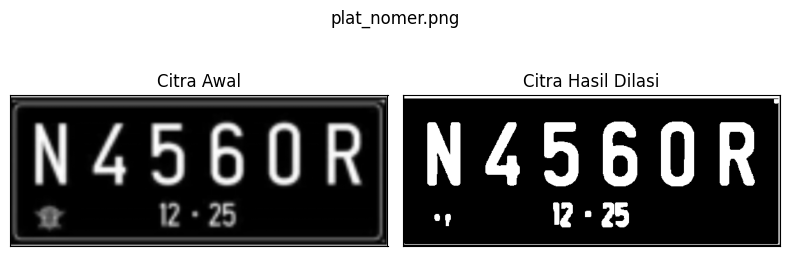

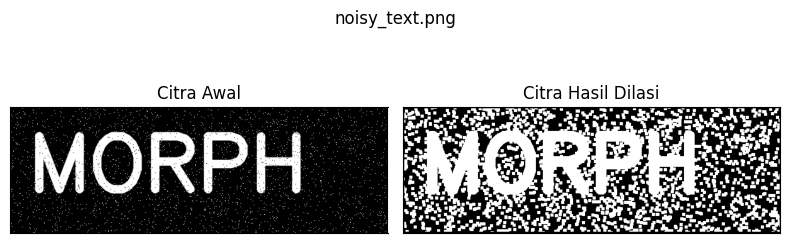

In [48]:
for nama in daftar_gambar:
    img_d= cv2.imread(folder + nama,0)
    ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)
    w=5
    imgD = dilasi_citra(thresh,w)

    plt.figure(figsize=(8,3))
    plt.subplot(121),plt.imshow(img_d,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(122),plt.imshow(imgD,cmap = 'gray')
    plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
    plt.suptitle(nama)
    plt.tight_layout()
    plt.show()

4. Buatlah program implementasi operasi dilasi Structuring Element Dilasi (SED)
berbentuk cross 3 x 3 dengan menggunakan library morphology dari openCV, sehingga
menghasilkan tampilan seperti di bawah ini:

[[1 1 1]
 [1 1 1]
 [1 1 1]]


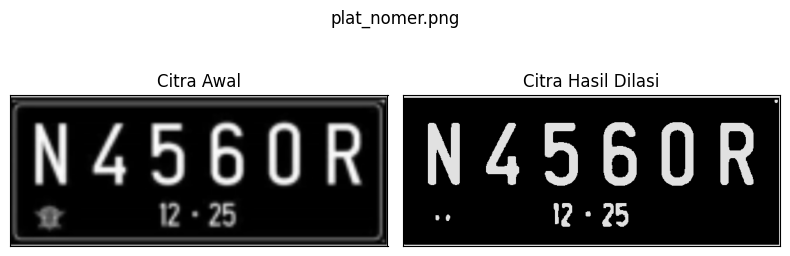

[[1 1 1]
 [1 1 1]
 [1 1 1]]


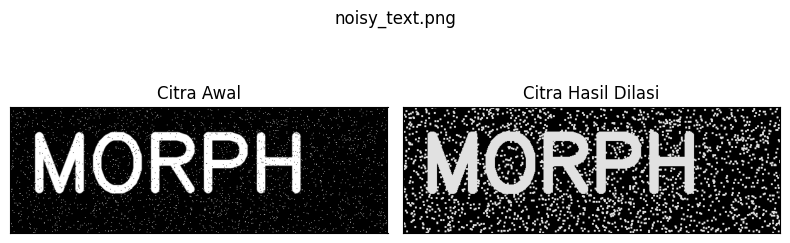

In [49]:
for nama in daftar_gambar:
    img = cv2.imread(folder + nama)
    ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
    kernel = np.ones((3,3),np.uint16)
    dilasi = cv2.dilate(thresh,kernel,iterations = 1)
    print(kernel)

    plt.figure(figsize=(8,3))
    plt.subplot(121),plt.imshow(img),plt.title('Citra Awal')
    plt.xticks([]), plt.yticks([])
    plt.subplot(122),plt.imshow(dilasi),plt.title('Citra Hasil Dilasi')
    plt.xticks([]), plt.yticks([])
    plt.suptitle(nama)
    plt.tight_layout()
    plt.show()

5. Buatlah fungsi erosi serta tampilkan hasil erosi pada citra dengan Structuring Element
Erosi (SE) berbentuk square 5 x 5 tanpa menggunakan library morphology dari openCV,
sehingga menghasilkan tampilan seperti di bawah ini:

In [50]:
#Erosi Tanpa Library

def erosi_citra(F,k):
  #size image
  m,n= F.shape

  #Generate structure element erosi (SE)
  SE= np.ones((k,k), dtype=np.uint8)
  constant= (k-1)//2

  imgE= np.zeros((m,n), dtype=np.uint8)

  #Proses Erosi
  for i in range(constant, m-constant):
    for j in range(constant,n-constant):
      temp= F[i-constant:i+constant+1, j-constant:j+constant+1]
      product= temp*SE
      imgE[i,j]= np.min(product)

  return imgE

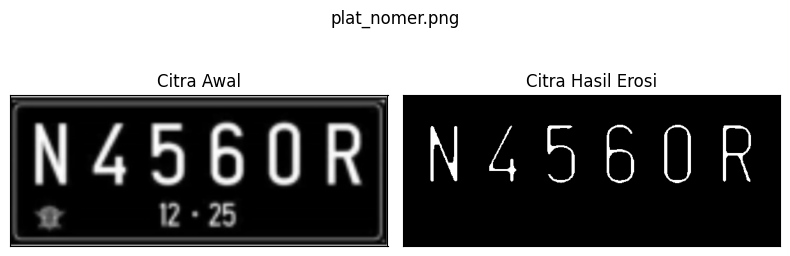

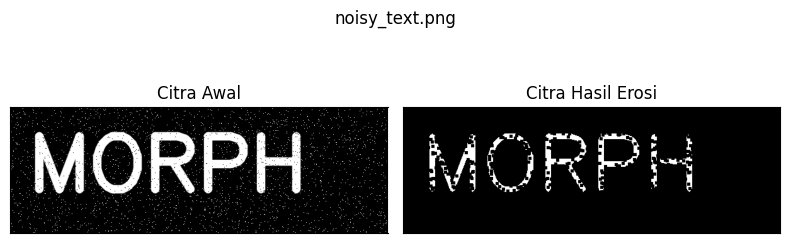

In [51]:
for nama in daftar_gambar:
    img_e= cv2.imread(folder + nama,0)
    ret1, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)
    k=5
    imgE = erosi_citra(thresh1,k)

    plt.figure(figsize=(8,3))
    plt.subplot(121),plt.imshow(img_e,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(122),plt.imshow(imgE,cmap = 'gray')
    plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
    plt.suptitle(nama)
    plt.tight_layout()
    plt.show()

6. Buatlah program implementasi operasi dilasi Structuring Element Erosi (SE) berbentuk
square 5 x 5 dengan menggunakan library morphology dari openCV, sehingga
menghasilkan tampilan seperti di bawah ini:

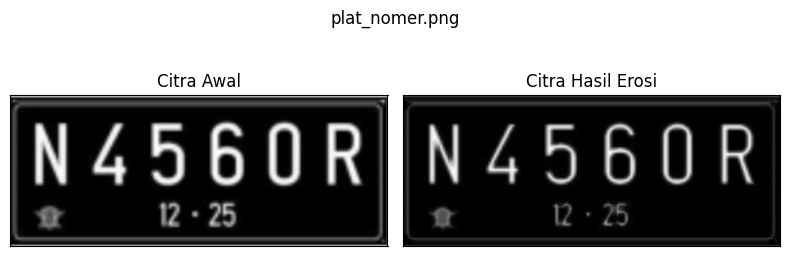

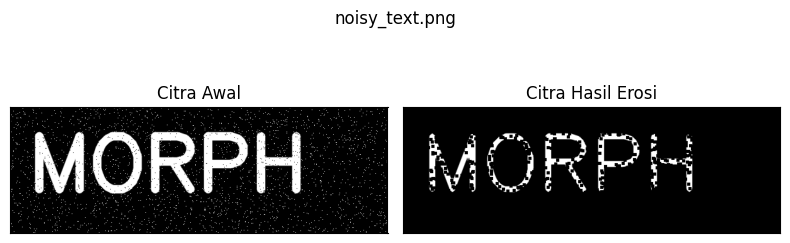

In [52]:
#EROSI LIBRARY
for nama in daftar_gambar:
    img = cv2.imread(folder + nama)

    kernel = np.ones((5,5),np.uint8)
    erosion = cv2.erode(img,kernel,iterations = 1)

    plt.figure(figsize=(8,3))
    plt.subplot(121),plt.imshow(img),plt.title('Citra Awal')
    plt.xticks([]), plt.yticks([])
    plt.subplot(122),plt.imshow(erosion),plt.title('Citra Hasil Erosi')
    plt.xticks([]), plt.yticks([])
    plt.suptitle(nama)
    plt.tight_layout()
    plt.show()

7. Buatlah program implementasi operasi opening dengan Structuring Element berbentuk
square 3 x 3 tanpa dan dengan menggunakan library morphology dari openCV,
sehingga menghasilkan tampilan seperti di bawah ini:

**Operasi Opening Menggunakan tanpa Library Morphology**

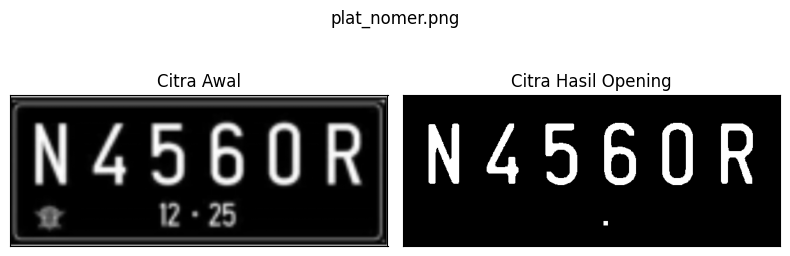

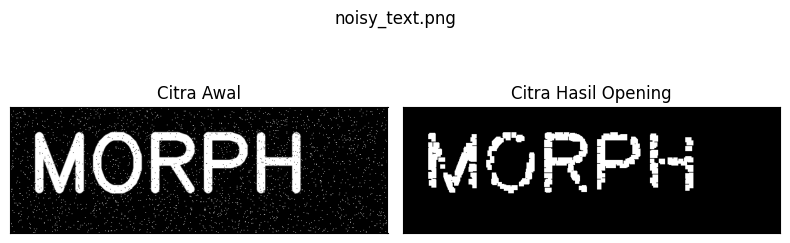

In [53]:
for nama in daftar_gambar:
    img_o= cv2.imread(folder + nama,0)
    reto, thresho = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)
    k=7
    imgO = dilasi_citra(erosi_citra(thresho,k),k)

    plt.figure(figsize=(8,3))
    plt.subplot(121),plt.imshow(img_o,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(122),plt.imshow(imgO,cmap = 'gray')
    plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
    plt.suptitle(nama)
    plt.tight_layout()
    plt.show()

**Operasi Opening Menggunakan Library Morphology**

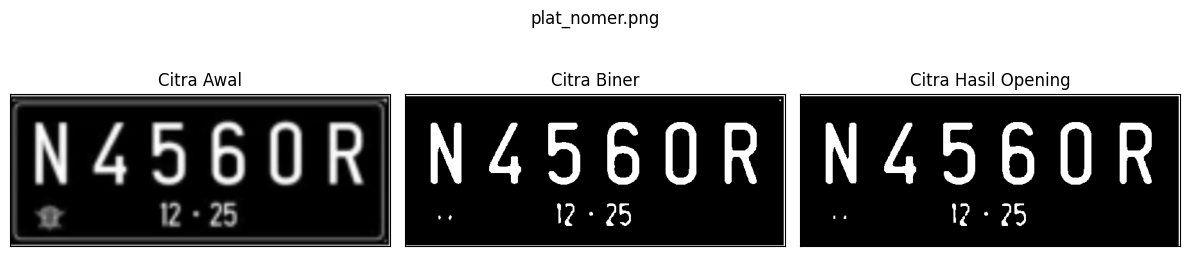

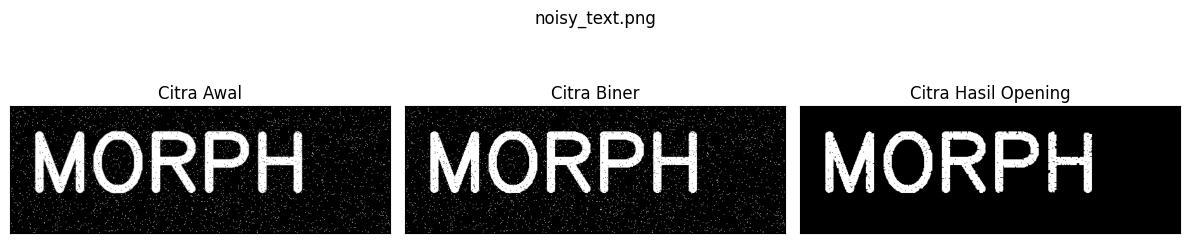

In [54]:
#Dengan Menggunakan Library
for nama in daftar_gambar:
    img = cv2.imread(folder + nama,0)
    ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
    kernel = np.ones((3,3),np.uint8)
    openn = cv2.morphologyEx(thresh,cv2.MORPH_OPEN, kernel)

    plt.figure(figsize=(12,3))
    plt.subplot(131),plt.imshow(img,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(thresh,cmap = 'gray')
    plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
    plt.subplot(133),plt.imshow(openn,cmap = 'gray')
    plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
    plt.suptitle(nama)
    plt.tight_layout()
    plt.show()

8. Buatlah program implementasi operasi closing dengan Structuring Element berbentuk
square 3 x 3 tanpa dan dengan menggunakan library morphology dari openCV,
sehingga menghasilkan tampilan seperti di bawah ini:

**operasi closing tanpa library morphology**

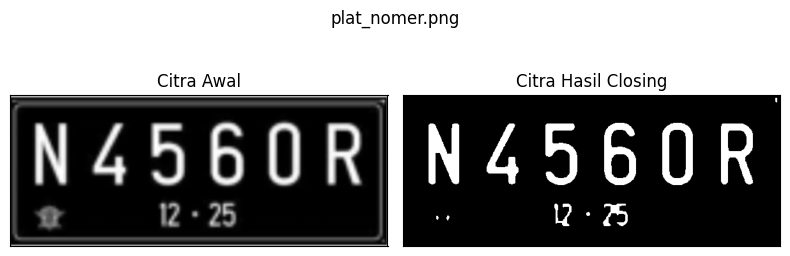

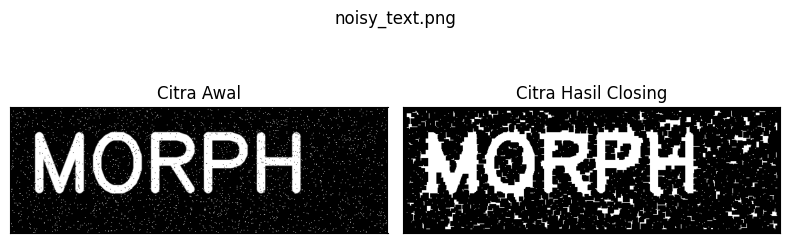

In [55]:
for nama in daftar_gambar:
    img_c= cv2.imread(folder + nama,0)
    retc, threshc = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)
    k=7
    imgC = erosi_citra(dilasi_citra(threshc,k),k)

    plt.figure(figsize=(8,3))
    plt.subplot(121),plt.imshow(img_c,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(122),plt.imshow(imgC,cmap = 'gray')
    plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
    plt.suptitle(nama)
    plt.tight_layout()
    plt.show()

**operasi closing dengan library morphology**

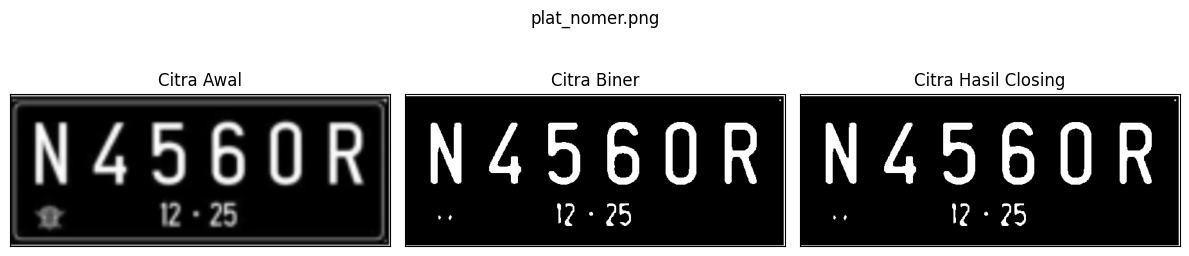

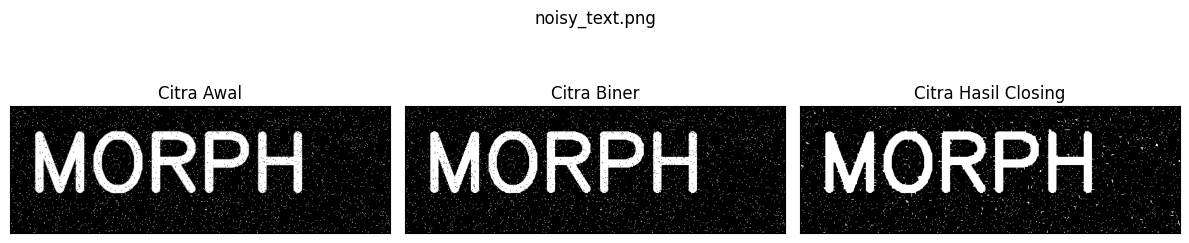

In [56]:
for nama in daftar_gambar:
    img = cv2.imread(folder + nama,0)
    ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
    kernel = np.ones((3,3),np.uint8)
    closs = cv2.morphologyEx(thresh,cv2.MORPH_CLOSE, kernel)

    plt.figure(figsize=(12,3))
    plt.subplot(131),plt.imshow(img,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(thresh,cmap = 'gray')
    plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
    plt.subplot(133),plt.imshow(closs,cmap = 'gray')
    plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
    plt.suptitle(nama)
    plt.tight_layout()
    plt.show()

9. Buatlah program implementasi operasi dilasi dengan Structuring Element berbentuk
Cross 3 x 3 dan 5 x 5, sehingga menghasilkan tampilan seperti di bawah ini:

**Cross 3**

In [57]:
#Dilasi Cross SED

def dilasi_citra(F,w):
  #size image
  p,q= F.shape

  imgD= np.zeros((p,q), dtype=np.uint8)
  #Generate structure element dilasi (SED)
  # SED= np.ones((w,w), dtype=np.uint8)
  SED = np.array([[0, 1, 0],
                  [1, 1, 1],
                  [0, 1, 0]], dtype = np.uint8)
  constant1= (w-1)//2

  #Proses Dilasi
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

SED = Cross 3


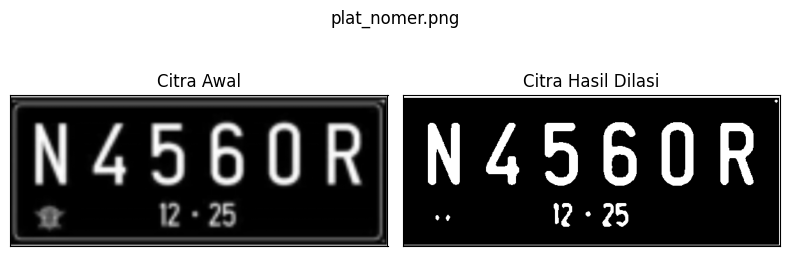

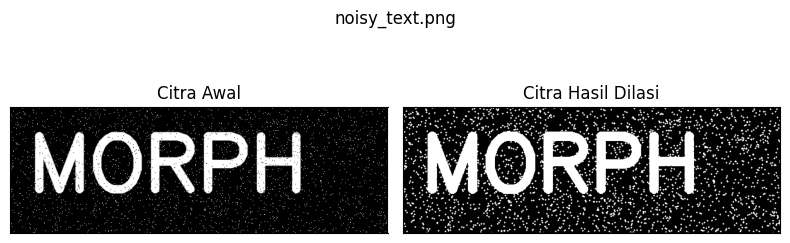

In [58]:
print('SED = Cross 3')
for nama in daftar_gambar:
    img_d= cv2.imread(folder + nama,0)
    ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
    w=3
    imgD = dilasi_citra(thresh,w)

    plt.figure(figsize=(8,3))
    plt.subplot(121),plt.imshow(img_d,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(122),plt.imshow(imgD,cmap = 'gray')
    plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
    plt.suptitle(nama)
    plt.tight_layout()
    plt.show()

**Cross 5**

In [59]:
def dilasi_citra(F,w):
  #size image
  p,q= F.shape

  imgD= np.zeros((p,q), dtype=np.uint8)

  #Generate structure element dilasi (SED)
  # SED= np.ones((w,w), dtype=np.uint8)
  SED = np.array([[0, 0, 1, 0, 0],
                  [0, 0, 1, 0, 0],
                  [1, 1, 1, 1, 1],
                  [0, 0, 1, 0, 0],
                  [0, 0, 1, 0, 0]], dtype = np.uint8)
  constant1= (w-1)//2

  #Proses Dilasi
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

SED = Cross 5


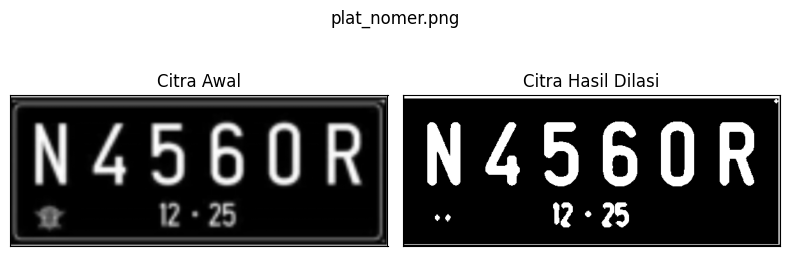

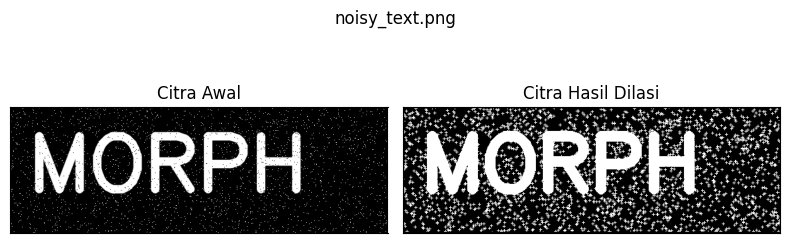

In [60]:
print('SED = Cross 5')
for nama in daftar_gambar:
    img_d= cv2.imread(folder + nama,0)
    ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
    w=5
    imgD = dilasi_citra(thresh,w)

    plt.figure(figsize=(8,3))
    plt.subplot(121),plt.imshow(img_d,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(122),plt.imshow(imgD,cmap = 'gray')
    plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
    plt.suptitle(nama)
    plt.tight_layout()
    plt.show()

10.Buatlah program implementasi operasi dilasi dengan Structuring Element berbentuk
Circular 3 x 3 dan 5 x 5, sehingga menghasilkan tampilan seperti di bawah ini:

In [61]:
#Dilasi Circular SED

def dilasi_citra(F,w):
  #size image
  p,q= F.shape

  imgD= np.zeros((p,q), dtype=np.uint8)

  #Generate structure element dilasi (SED)
  SED= cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(w,w))
  constant1= (w-1)//2

  #Proses Dilasi
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

**Circular 3 x 3**

SED = Circle 3


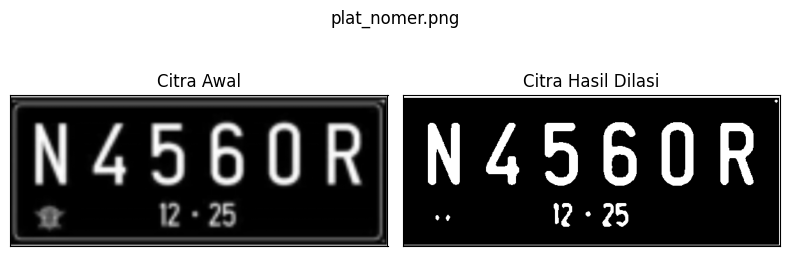

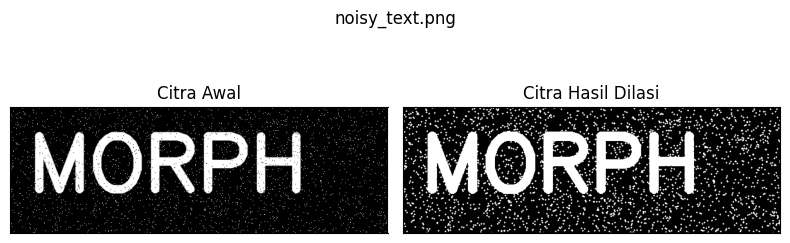

In [62]:
print('SED = Circle 3')
for nama in daftar_gambar:
    img_d= cv2.imread(folder + nama,0)
    ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
    w=3
    imgD = dilasi_citra(thresh,w)

    plt.figure(figsize=(8,3))
    plt.subplot(121),plt.imshow(img_d,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(122),plt.imshow(imgD,cmap = 'gray')
    plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
    plt.suptitle(nama)
    plt.tight_layout()
    plt.show()

**Circular 5 x 5**

SED = Circle 5


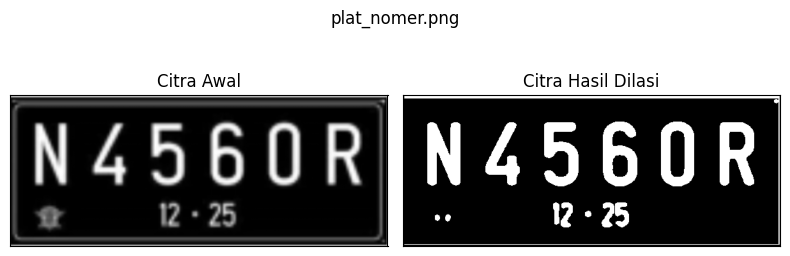

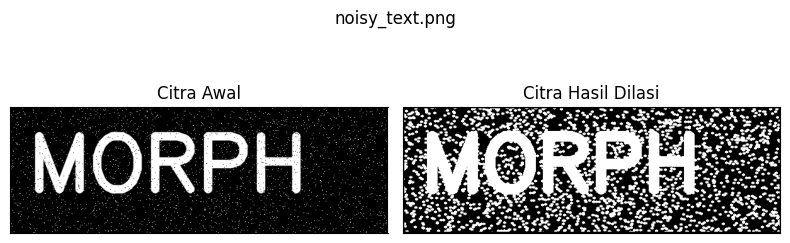

In [63]:
print('SED = Circle 5')
for nama in daftar_gambar:
    img_d= cv2.imread(folder + nama,0)
    ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
    w=5
    imgD = dilasi_citra(thresh,w)

    plt.figure(figsize=(8,3))
    plt.subplot(121),plt.imshow(img_d,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(122),plt.imshow(imgD,cmap = 'gray')
    plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
    plt.suptitle(nama)
    plt.tight_layout()
    plt.show()

11.Buatlah program implementasi operasi erosi dengan Structuring Element berbentuk
Rectangle 3 x 5 dan 5 x 7, sehingga menghasilkan tampilan seperti di bawah ini:

In [64]:
#Erosi Cross SE

def erosi_citra(F,p,l):
  #size image
  m,n= F.shape

  #Generate structure element erosi (SE)
  SE = cv2.getStructuringElement(cv2.MORPH_RECT,(p,l)) #SE persegi panjang
  constant1= (l-1)//2
  constant2= (p-1)//2
  # print(SE)
  imgE= np.zeros((m,n), dtype=np.uint8)

  #Proses Erosi
  for i in range(constant1, m-constant1):
    for j in range(constant2,n-constant2):
      temp= F[i-constant1:i+constant1+1, j-constant2:j+constant2+1]
      product= temp*SE
      imgE[i,j]= np.min(product)

  return imgE

**Rectangle 3 x 5**

SE = Rectangle 3x5


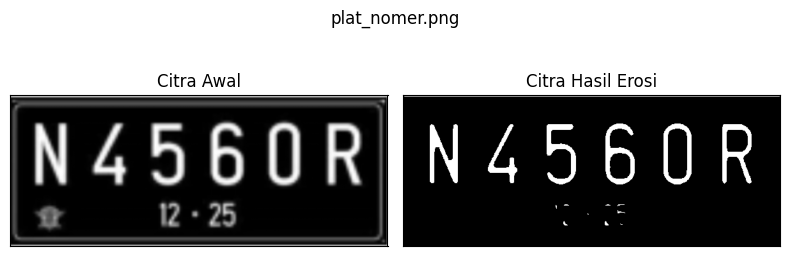

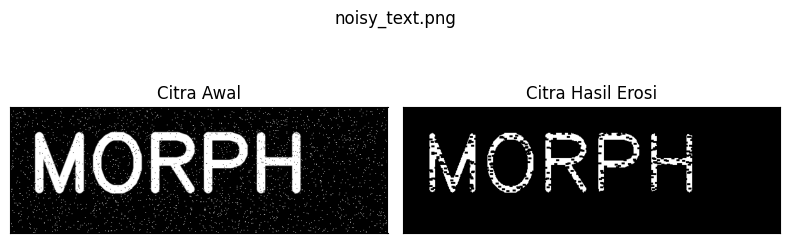

In [65]:
print('SE = Rectangle 3x5')
for nama in daftar_gambar:
    img_e= cv2.imread(folder + nama,0)
    ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
    p=5
    l=3
    imgE = erosi_citra(thresh1,p,l)

    plt.figure(figsize=(8,3))
    plt.subplot(121),plt.imshow(img_e,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(122),plt.imshow(imgE,cmap = 'gray')
    plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
    plt.suptitle(nama)
    plt.tight_layout()
    plt.show()

**Rectangle 5 x 7**

SE = Rectangle 5x7


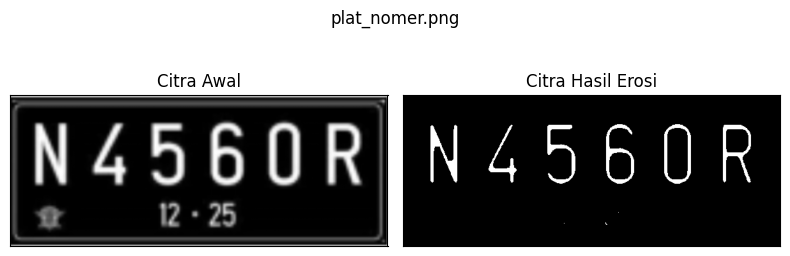

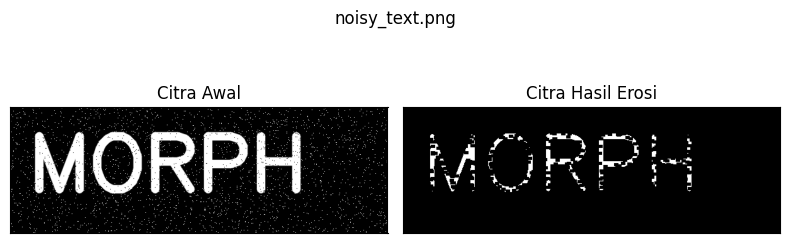

In [66]:
print('SE = Rectangle 5x7')
for nama in daftar_gambar:
    img_e= cv2.imread(folder + nama,0)
    ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
    p=7
    l=5
    imgE = erosi_citra(thresh1,p,l)

    plt.figure(figsize=(8,3))
    plt.subplot(121),plt.imshow(img_e,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(122),plt.imshow(imgE,cmap = 'gray')
    plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
    plt.suptitle(nama)
    plt.tight_layout()
    plt.show()

12.Buatlah program implementasi operasi erosi dengan Structuring Element berbentuk Line
Vertikal 3 dan 5, sehingga menghasilkan tampilan seperti di bawah ini: (Gunakan
gambar j.png)

In [67]:
#Erosi Line Vertikal SE

def erosi_citra(F,k):
  #size image
  m,n= F.shape

  #Generate structure element erosi (SE)
  SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(1,k)) #SE line vertikal
  constant= (k-1)//2

  imgE= np.zeros((m,n), dtype=np.uint8)

  #Proses Erosi
  for i in range(constant, m-constant):
    for j in range(constant,n-constant):
      temp= F[i-constant:i+constant+1, j-constant:j+constant+1]
      product= temp*SE
      imgE[i,j]= np.min(product)

  return imgE

**Line Vertikal 3**

SE = Line Vertikal 3


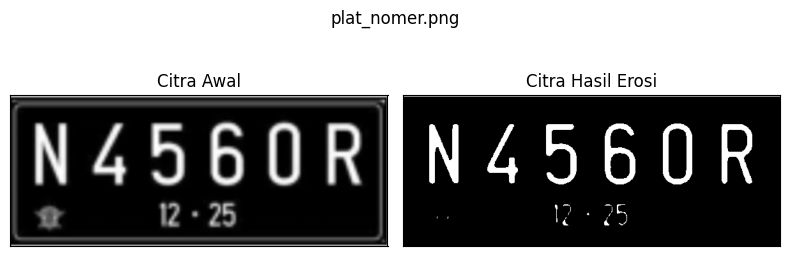

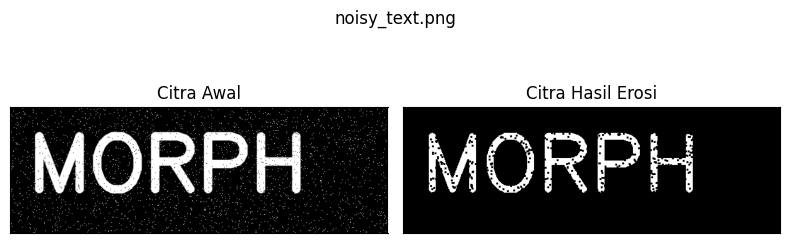

In [68]:
print('SE = Line Vertikal 3')
for nama in daftar_gambar:
    img_e= cv2.imread(folder + nama,0)
    ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
    k=3
    imgE = erosi_citra(thresh1,k)

    plt.figure(figsize=(8,3))
    plt.subplot(121),plt.imshow(img_e,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(122),plt.imshow(imgE,cmap = 'gray')
    plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
    plt.suptitle(nama)
    plt.tight_layout()
    plt.show()

**Line Vertikal 5**

SE = Line Vertikal 5


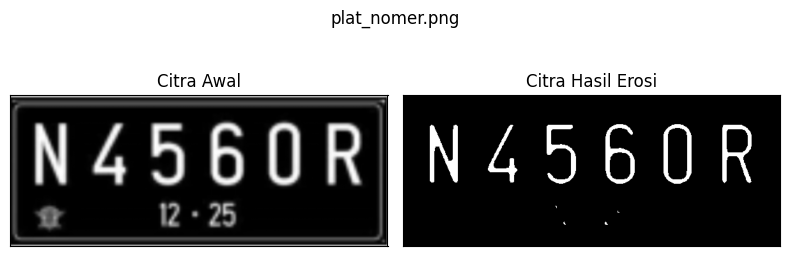

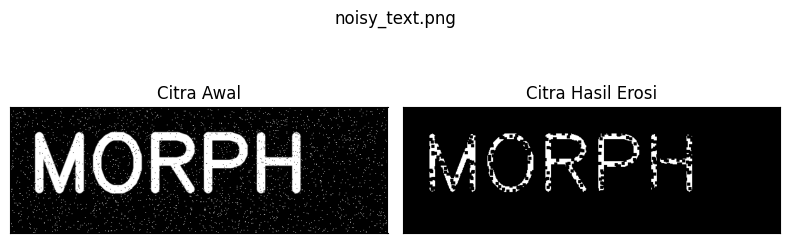

In [69]:
print('SE = Line Vertikal 5')
for nama in daftar_gambar:
    img_e= cv2.imread(folder + nama,0)
    ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
    k=5
    imgE = erosi_citra(thresh1,k)

    plt.figure(figsize=(8,3))
    plt.subplot(121),plt.imshow(img_e,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(122),plt.imshow(imgE,cmap = 'gray')
    plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
    plt.suptitle(nama)
    plt.tight_layout()
    plt.show()

13.Buatlah program transformasi Top-hat dengan structuring element 3 × 3, lalu tampilkan
citra asal dan hasilnya secara berdampingan.https://colab.research.google.com/

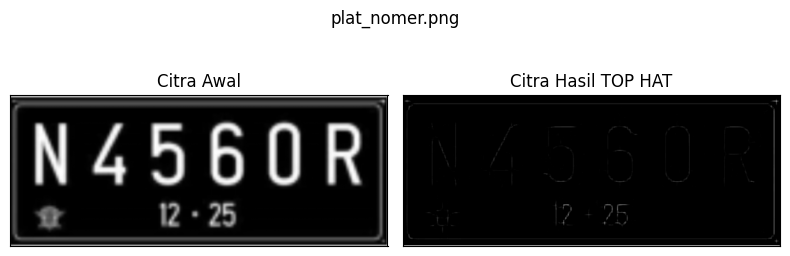

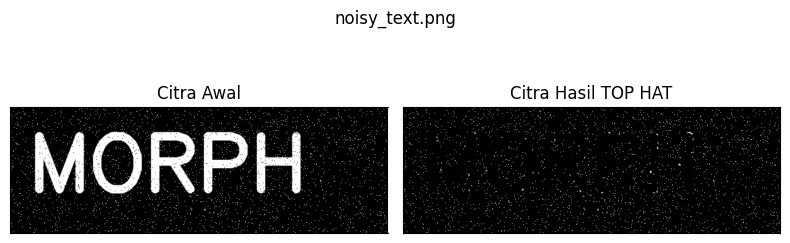

In [72]:
filterSize =(3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

for nama in daftar_gambar:
    img = cv2.imread(folder + nama)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Applying the Top-Hat operation
    tophat_img = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)

    plt.figure(figsize=(8,3))
    plt.subplot(121),plt.imshow(img,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(122),plt.imshow(tophat_img,cmap = 'gray')
    plt.title('Citra Hasil TOP HAT'), plt.xticks([]), plt.yticks([])
    plt.suptitle(nama)
    plt.tight_layout()
    plt.show()

14.Buatlah program transformasi Black-hat dengan structuring element 3 × 3. Ingat, Black-
hat adalah hasil closing dikurangi citra asal.https://colab.research.google.com/

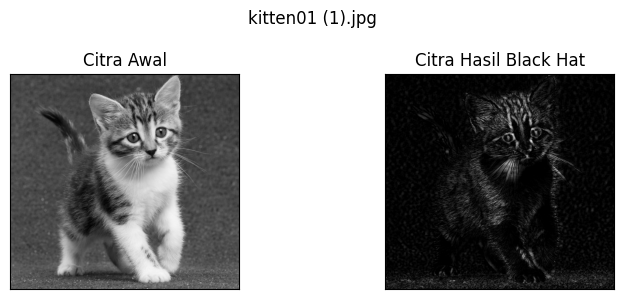

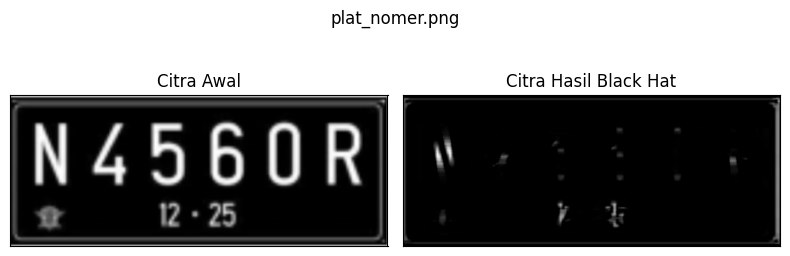

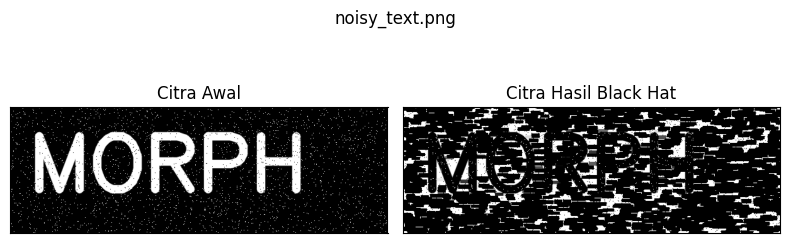

In [75]:
daftar_14 = ['kitten01 (1).jpg', 'plat_nomer.png', 'noisy_text.png']

filterSize =(3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

for nama in daftar_14:
    img = cv2.imread(folder + nama)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Applying the Black-Hat operation
    Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
    blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, Kernel)

    plt.figure(figsize=(8,3))
    plt.subplot(121),plt.imshow(img,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(122),plt.imshow(blackhat,cmap = 'gray')
    plt.title('Citra Hasil Black Hat'), plt.xticks([]), plt.yticks([])
    plt.suptitle(nama)
    plt.tight_layout()
    plt.show()

15.Buatlah program skeleton pada citra biner, lalu tampilkan citra biner dan rangkanya
secara berdampingan.https://colab.research.google.com/

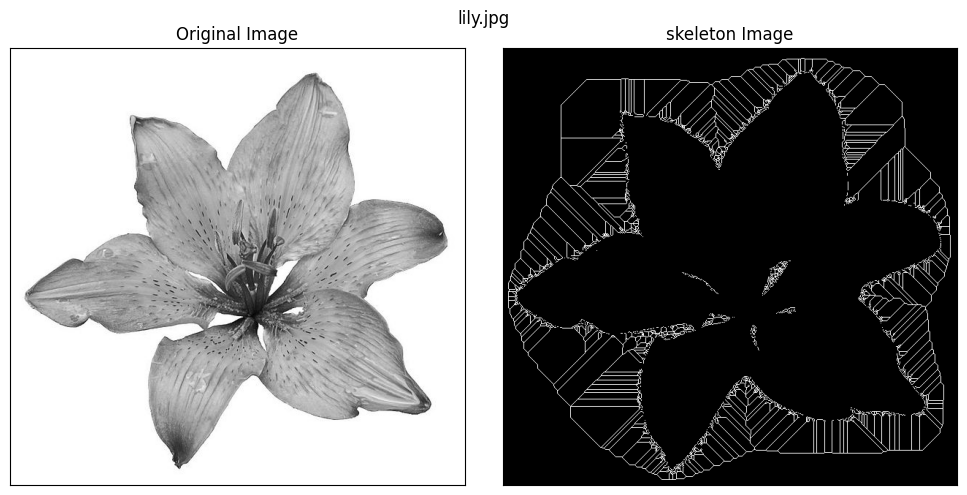

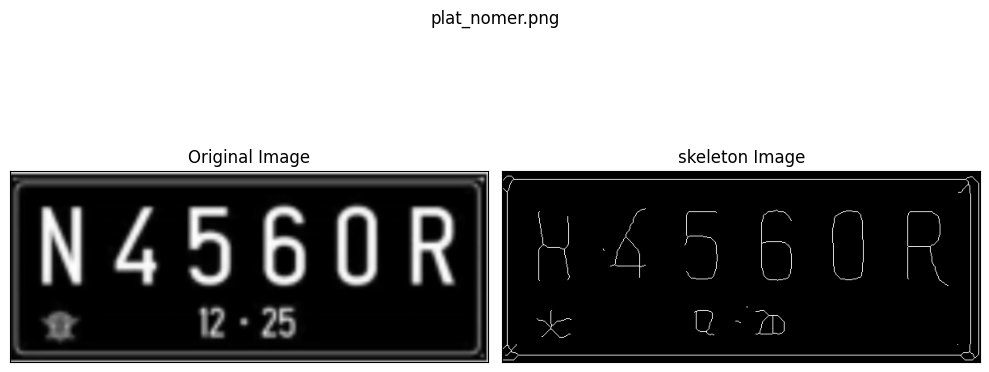

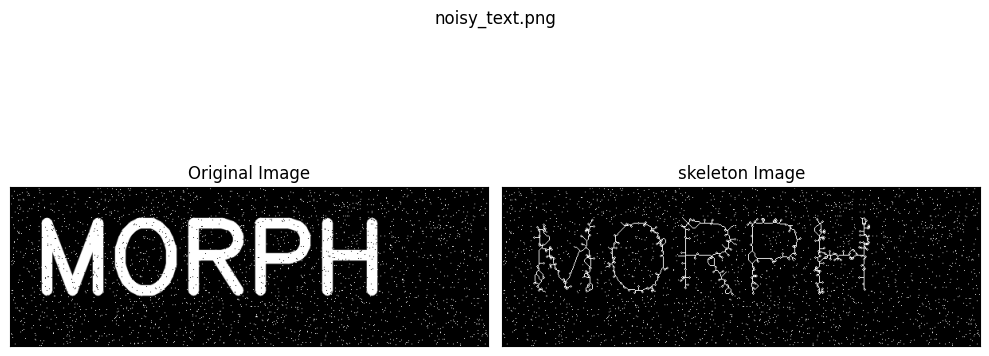

In [76]:
import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

daftar_15 = ['lily.jpg', 'plat_nomer.png', 'noisy_text.png']

for nama in daftar_15:
    # read image
    img = cv.imread(folder + nama,0)

    binary = img > filters.threshold_triangle(img)

    # true false to one
    binary_cp = binary.copy()
    binary_cp[binary_cp == True] = 1
    binary_cp[binary_cp == False] = 0

    # skeletonize image
    skeleton = skeletonize(binary_cp)

    # print images
    plt.figure(figsize=(10,5))

    plt.subplot(121),plt.imshow(img,cmap = 'gray')
    plt.title('Original Image'), plt.xticks([]), plt.yticks([])

    plt.subplot(122),plt.imshow(skeleton,cmap = 'gray')
    plt.title('skeleton Image'), plt.xticks([]), plt.yticks([])

    plt.suptitle(nama)
    plt.tight_layout()
    plt.savefig("binary and bin_skeleton_" + nama + ".png")
    plt.show()

16.Buatlah program skeleton pada citra hasil inversi, lalu bandingkan hasilnya dengan
langkah sebelumnya.https://colab.research.google.com/

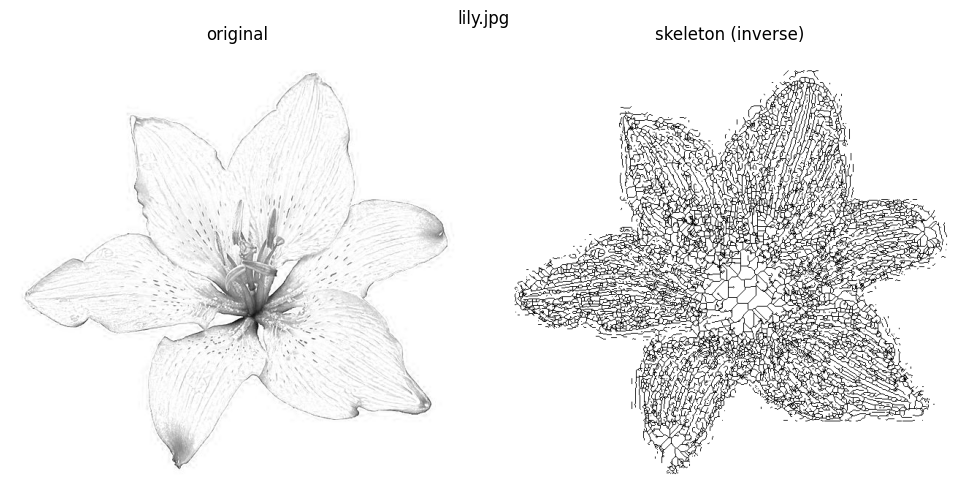

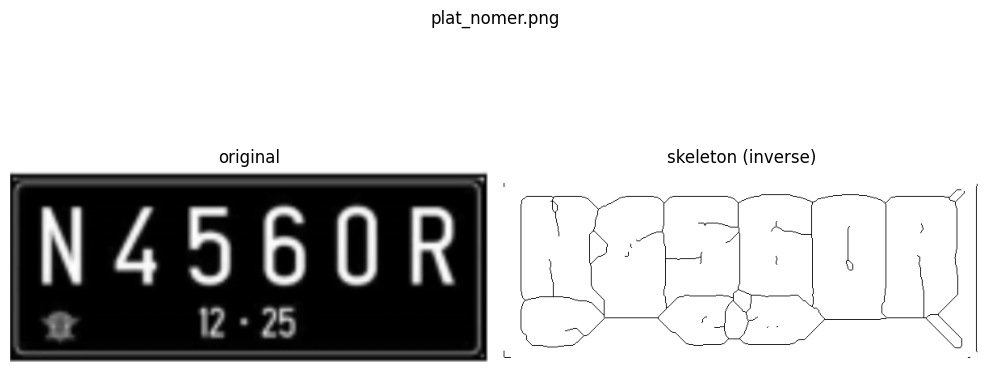

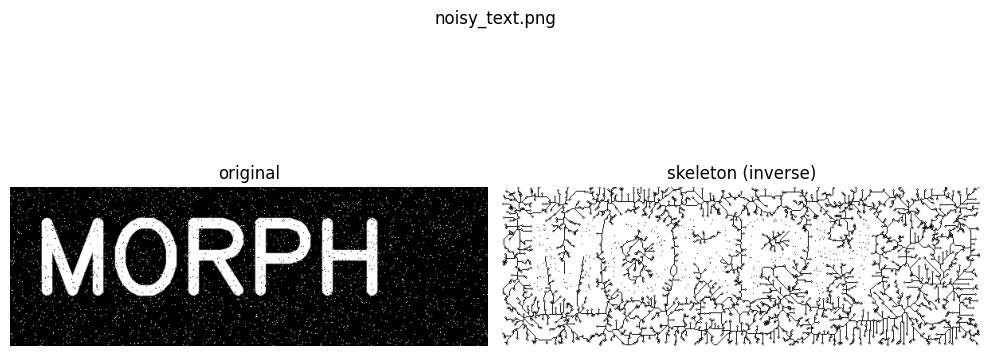

In [78]:
from skimage import io
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

daftar_16 = ['lily.jpg', 'plat_nomer.png', 'noisy_text.png']

for nama in daftar_16:
    # read image
    img = io.imread(folder + nama)
    if img.ndim == 3:
        img = img[..., 0]

    # Note: we want the black bits to be True, so use <
    binary = img < filters.threshold_triangle(img)

    # skeletonize image
    skeleton = skeletonize(binary)

    # print images
    fig, ax = plt.subplots(1, 2, figsize=(10,5))

    ax[0].imshow(img, cmap='gray')
    ax[0].set_title('original')
    ax[0].set_axis_off()

    # note the reversed colormap, gray_r
    ax[1].imshow(skeleton, cmap='gray_r')
    ax[1].set_title('skeleton (inverse)')
    ax[1].set_axis_off()

    plt.suptitle(nama)
    plt.tight_layout()
    plt.show()

17.Buatlah program thinning memakai morphology.thin(), lalu bandingkan hasilnya dengan
skeleton pada langkah 15.https://colab.research.google.com/

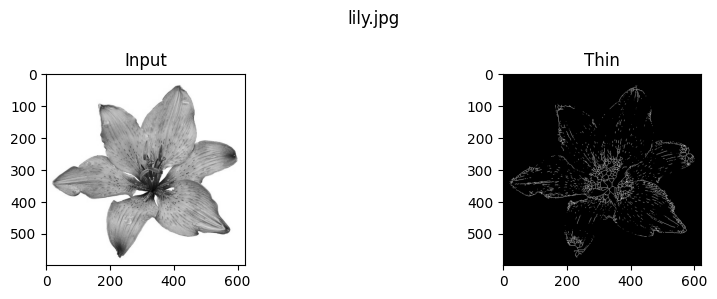

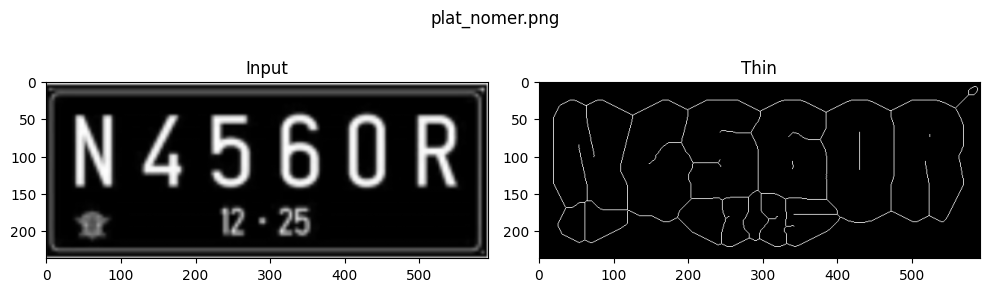

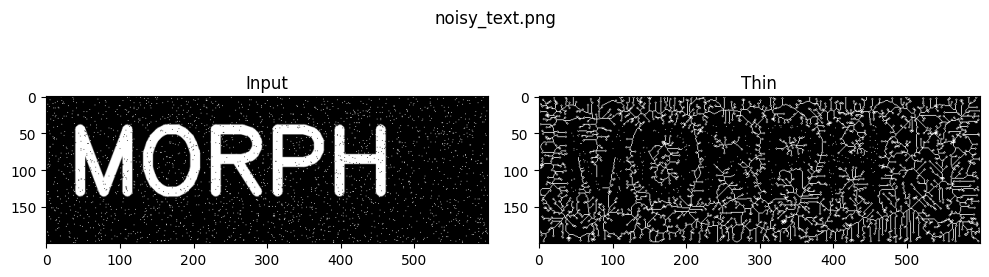

In [80]:
from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt

daftar_17 = ['lily.jpg', 'plat_nomer.png', 'noisy_text.png']

for nama in daftar_17:
    img = io.imread(folder + nama)

    # buang channel alpha kalau RGBA, abaikan konversi kalau sudah grayscale
    if img.ndim == 3:
        img = img[..., :3]
        image = img_as_float(color.rgb2gray(img))
    else:
        image = img_as_float(img)

    image_binary = image < 0.5
    out_skeletonize = morphology.skeletonize(image_binary)
    out_thin = morphology.thin(image_binary)

    f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3))

    ax0.imshow(image, cmap='gray')
    ax0.set_title('Input')

    ax1.imshow(out_thin, cmap='gray')
    ax1.set_title('Thin')

    plt.suptitle(nama)
    plt.tight_layout()
    plt.savefig('/tmp/char_out.png')
    plt.show()